### Spherical collapse


In [1]:
import os, sys
sys.path.append('../scripts')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from exercise_4 import *

FIG, DATA = '../report_ex4/figures/', '../report_ex4/data/'   # outputs used by the LaTeX report
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
pd.set_option('display.float_format', '{:.8g}'.format)
pd.set_option('display.width', 200)

COLS = ['formulation', 'Omega_m0', 'z_c', 'delta_i', 'bracket', 'iterations', 'event_residual', 'nfev',
        'a_ta', 'a_ta_over_a_c', 'zeta_ta', 'delta_c', 'lambda_ta', 'y', 'Delta_vir_m', 'Delta_vir_c']

#### Formulations A, B, C

For $N=\ln a$, $A_H = 2+\mathrm{d}\ln H/\mathrm{d}N$, $\vartheta=\nabla_x\cdot\boldsymbol v/(aH)$, $g=1/\delta$,

\begin{equation}
    A: \frac{d^2\delta}{dN^2} = - A_H \frac{d\delta}{dN} + \frac{4}{3} \frac{(\frac{d\delta}{dN})^2}{(1 + \delta)} + \frac{3}{2} \Omega_m\delta (1 + \delta) \nonumber
\end{equation}

\begin{equation}
    B: \frac{\mathrm{d}\delta}{\mathrm{d}N} = -(1+\delta)\,\vartheta, \qquad
\frac{\mathrm{d}\vartheta}{\mathrm{d}N} = -A_H\,\vartheta - \frac{\vartheta^2}{3} - \frac{3}{2}\,\Omega_m\,\delta \nonumber
\end{equation}

\begin{equation}
    C: \frac{\mathrm{d}g}{\mathrm{d}N} = g\,(1+g)\,\vartheta, \qquad
\frac{\mathrm{d}\vartheta}{\mathrm{d}N} = -A_H\,\vartheta - \frac{\vartheta^2}{3} - \frac{3\,\Omega_m}{2g} \nonumber
\end{equation}

The same state $(N,\delta,\vartheta)$ is written in each formulation's variables ($\delta_N=-(1+\delta)\vartheta$ for A, $g=1/\delta$ for C) and compared through B:
- A vs B: $\delta_{NN}^A$ vs $-\delta_N\vartheta-(1+\delta)\vartheta_N^B$
- C vs B: $-\delta^2 g_N^C$ vs $\delta_N^B$, and $\vartheta_N^C$ vs $\vartheta_N^B$

Printed: max $|x_1/x_2-1|$ over 20 random states


In [2]:
# check of algebraic equivalence in independent implementations
rng = np.random.default_rng(1)
for Om0 in [1.0, 0.3]:
    a, b, c = A(Om0), B(Om0), C(Om0)   
    errors = []
    for N, d, th in zip(rng.uniform(-10, 0, 20), 10**rng.uniform(-5, 6, 20), -10**rng.uniform(-5, 3, 20)):
        dN_B, thN_B = b.rhs(N, [d, th])              # B in (delta, theta)
        _, dNN_A = a.rhs(N, [d, dN_B])               # A in (delta, delta_N), with delta_N = -(1+delta) theta
        gN_C, thN_C = c.rhs(N, [1/d, th])            # C in (g, theta), with g = 1/delta
        dNN_B = -dN_B*th - (1 + d)*thN_B             # derivative of B's continuity equation
        errors.append([abs(dNN_A/dNN_B - 1),         # A vs B: delta_NN
                       abs(-d**2*gN_C/dN_B - 1),     # C vs B: delta_N = -delta^2 g_N
                       abs(thN_C/thN_B - 1)])        # C vs B: theta_N
    print(f'Omega_m0 = {Om0}: max relative differences (A vs B, C vs B delta_N, C vs B theta_N) =',
          np.max(errors, axis=0))

Omega_m0 = 1.0: max relative differences (A vs B, C vs B delta_N, C vs B theta_N) = [3.33066907e-16 4.44089210e-16 2.22044605e-16]
Omega_m0 = 0.3: max relative differences (A vs B, C vs B delta_N, C vs B theta_N) = [3.33066907e-16 2.22044605e-16 2.22044605e-16]


#### Growing-mode initial conditions
$\delta_{N,i}=f_i\delta_i$ (A), $\vartheta_i=-f_i\delta_i/(1+\delta_i)$ (B, C), $g_i=1/\delta_i$ (C), and for the linear equation $\delta_{L,i}=\delta_i$,   $\delta_{L,N,i}=f_i\delta_i$.

$f_i$ is calculated from Exercise 1 at $a_i$ (with ODE evaluated starting at $10^{-3}a_i$).


In [3]:
# growth rate at the initial epoch 
# expected values: f_i = 1 in EdS, and -> 1 in LCDM for early a_i (matter domination)
for Om0 in [1.0, 0.2, 0.3, 0.4]:
    print(f'Omega_m0 = {Om0}:', ', '.join(f'1 - f_i(a_i={ai:.0e}) = {1 - A(Om0, a_i=ai).f_i:.2e}'
                                          for ai in [1e-3, 1e-4, 1e-5]))

Omega_m0 = 1.0: 1 - f_i(a_i=1e-03) = -2.22e-16, 1 - f_i(a_i=1e-04) = 2.22e-16, 1 - f_i(a_i=1e-05) = -8.88e-16
Omega_m0 = 0.2: 1 - f_i(a_i=1e-03) = 2.18e-09, 1 - f_i(a_i=1e-04) = 2.18e-12, 1 - f_i(a_i=1e-05) = 1.33e-15
Omega_m0 = 0.3: 1 - f_i(a_i=1e-03) = 1.27e-09, 1 - f_i(a_i=1e-04) = 1.27e-12, 1 - f_i(a_i=1e-05) = 1.55e-15
Omega_m0 = 0.4: 1 - f_i(a_i=1e-03) = 8.18e-10, 1 - f_i(a_i=1e-04) = 8.19e-13, 1 - f_i(a_i=1e-05) = 5.55e-16


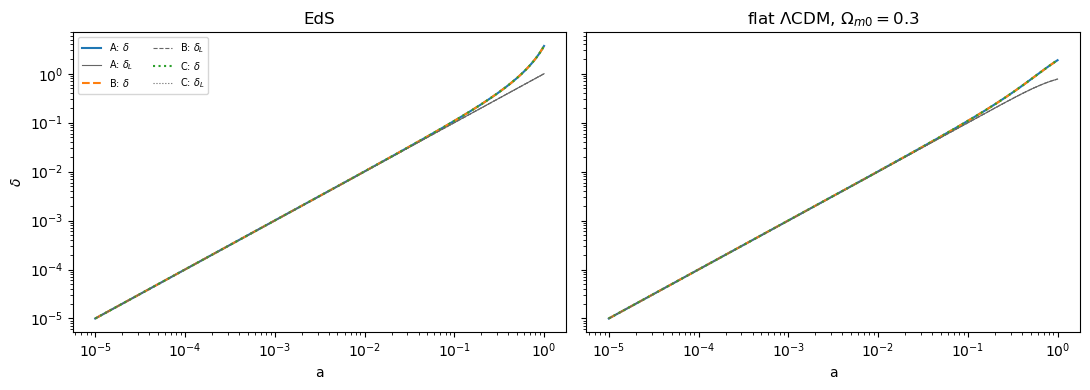

In [4]:
# A, B, C integrated together with linear counterpart for one trial amplitude
a_i, delta_i = 1e-5, 1e-5
a = np.logspace(-5, 0, 300) # where solution is evaluated

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, Om0, title in zip(ax, [1.0, 0.3], ['EdS', r'flat $\Lambda$CDM, $\Omega_{m0}=0.3$']):
    for F, ls in zip((A, B, C), ['-', '--', ':']):
        sol = F(Om0, a_i=a_i).integrate(delta_i, N_end=0.0) # from a_i to a = 1
        y = sol.sol(np.log(a))  # state [y0, y1, delta_L, delta_L_N] at each a
        d = 1/y[0] if F is C else y[0]  # C integrates g = 1/delta
        axis.loglog(a, d, ls, label=f'{F.__name__}: $\\delta$')
        axis.loglog(a, y[2], ls, lw=0.8, color='0.4', label=f'{F.__name__}: $\\delta_L$')
    axis.set(xlabel='a', title=title)
ax[0].set_ylabel(r'$\delta$'); ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()


#### Collapse epoch
For $a_c=(1+z_c)^{-1}$, $\delta_i$ is tuned with `brentq` until the collapse event ($\delta=\delta_\infty$ for A, B; $g=\epsilon$ for C) happens at $a_c$; then $\delta_c=\delta_L(a_c)$.

Residual: $N_{\rm coll}(\delta_i)-N_c$ (integration to $N_c+0.5$). Bracket: $\pm3\%$ around $1.686\,D(a_i)/D(a_c)$, widened until the sign changes.

For $a_i=10^{-5}$, $\delta_\infty=10^8$ (A, B), $\epsilon=10^{-8}$ (C), ODEs are solved with method DOP853 with `rtol=1e-10`, `atol=1e-13`.

In [5]:
# tuned runs: delta_i, delta_c, root-search record and settings for A, B, C (EdS and LCDM, z_c = 0)
tuned = pd.DataFrame([F(Om0).tune_delta_i(z_c=0.0) for Om0 in [1.0, 0.3] for F in (A, B, C)])
tuned

,formulation,Omega_m0,z_c,delta_i,delta_c,bracket,iterations,event_residual,nfev,a_i,threshold,rtol,atol
0,A,1,0,1.6863898e-05,1.6863898,"(1.6358760974255843e-05, 1.7370643096374765e-05)",6,4.5287444e-15,2357,1e-05,1e+08,1e-10,1e-13
1,B,1,0,1.6863898e-05,1.6863898,"(1.6358760974255843e-05, 1.7370643096374765e-05)",6,-4.2191759e-15,2483,1e-05,1e+08,1e-10,1e-13
2,C,1,0,1.6863898e-05,1.6863898,"(1.6358760974255843e-05, 1.7370643096374765e-05)",6,4.5310037e-15,3101,1e-05,1e-08,1e-10,1e-13
3,A,0.3,0,2.150836e-05,1.6754604,"(2.100020491051875e-05, 2.229918665756115e-05)",7,-8.3296438e-15,2297,1e-05,1e+08,1e-10,1e-13
4,B,0.3,0,2.150836e-05,1.6754604,"(2.100020491051875e-05, 2.229918665756115e-05)",7,1.8594462e-15,2339,1e-05,1e+08,1e-10,1e-13
5,C,0.3,0,2.150836e-05,1.6754604,"(2.100020491051875e-05, 2.229918665756115e-05)",7,-8.0466222e-16,2942,1e-05,1e-08,1e-10,1e-13


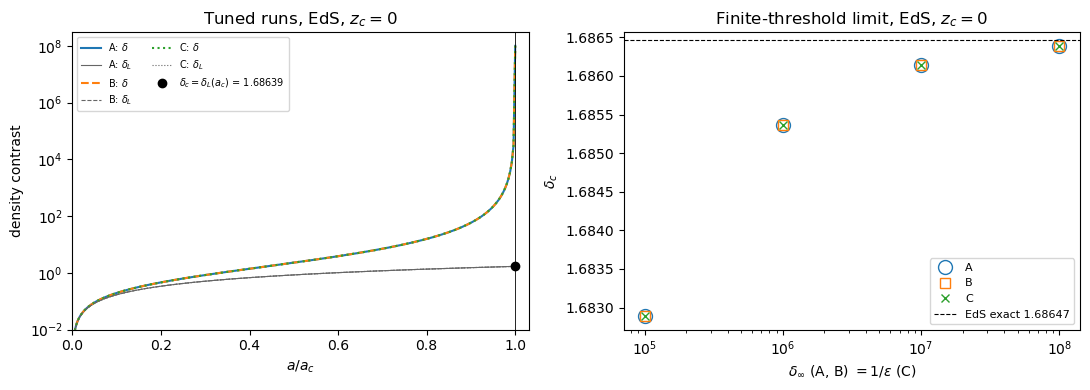

In [6]:
z_c = 0.0
N_c = -np.log(1 + z_c)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# left: tuned trajectories up to collapse and delta_c read at a_c
for F, ls in zip((A, B, C), ['-', '--', ':']):
    model = F(1.0)
    r = model.tune_delta_i(z_c)
    sol = model.integrate(r['delta_i'], N_end=N_c + 0.5)              # same run as the tuned one
    N = np.linspace(np.log(model.a_i), sol.t_events[0][0], 3000)      # up to the collapse event
    y = sol.sol(N)
    d = 1/y[0] if F is C else y[0]                                    # C integrates g = 1/delta
    ax[0].semilogy(np.exp(N - N_c), d, ls, label=f'{F.__name__}: $\\delta$')
    ax[0].semilogy(np.exp(N - N_c), y[2], ls, lw=0.8, color='0.4', label=f'{F.__name__}: $\\delta_L$')
ax[0].axvline(1, color='k', lw=0.6)
ax[0].plot(1, r['delta_c'], 'ko', label=f'$\\delta_c=\\delta_L(a_c)$ = {r["delta_c"]:.5f}')
ax[0].set(xlim=(0, 1.03), ylim=(1e-2, 3e8), xlabel=r'$a/a_c$', ylabel='density contrast',
          title=r'Tuned runs, EdS, $z_c=0$')
ax[0].legend(fontsize=7, ncol=2)

# right: threshold limit, delta_c for each threshold
thresholds = np.array([1e5, 1e6, 1e7, 1e8])
for F, m, s in zip((A, B, C), ['o', 's', 'x'], [10, 7, 6]):
    dc = [F(1.0, threshold=(1/t if F is C else t)).tune_delta_i(z_c)['delta_c'] for t in thresholds]
    ax[1].semilogx(thresholds, dc, m, ms=s, mfc='none', label=F.__name__)
ax[1].axhline(DELTA_C_EDS, color='k', ls='--', lw=0.8, label='EdS exact 1.68647')
ax[1].set(xlabel=r'$\delta_\infty$ (A, B) $= 1/\epsilon$ (C)', ylabel=r'$\delta_c$',
          title=r'Finite-threshold limit, EdS, $z_c=0$')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


The 3 formulations A, B, C reach the threshold at $a_c$ with $|\ln(a_{\rm coll}/a_c)|\lesssim10^{-14}$ and return the same $\delta_c$. As the threshold grows, $\delta_c$ increases.


#### Turnaround and virial prescription

**Turnaround:** $\vartheta(a_{\rm ta}) = -3$, $\quad \zeta_{\rm ta} = 1+\delta(a_{\rm ta})$, with $\vartheta=-\delta_N/(1+\delta)$ in A and $\delta = 1/g$ in C.

**Virial prescription**:
$$\lambda_{\rm ta} = \frac{\Omega_\Lambda(a_{\rm ta})}{\Omega_m(a_{\rm ta})\,\zeta_{\rm ta}}, \qquad
4\lambda_{\rm ta}y^3 - 2(1+\lambda_{\rm ta})\,y + 1 = 0, \quad y = \frac{R_{\rm vir}}{R_{\rm ta}} \in (0, 1/2]\ \ (y = 1/2 \text{ in EdS})$$
$$\Delta_{{\rm vir},m}(a_c) = \zeta_{\rm ta}\left(\frac{a_c}{a_{\rm ta}}\right)^3 y^{-3}, \qquad
\Delta_{{\rm vir},c}(a_c) = \Omega_m(a_c)\,\Delta_{{\rm vir},m}(a_c)$$



In [7]:
# virial_y
for lam in [0.0, 1e-8, 1e-4, 0.01, 0.06, 0.1]:
    y = virial_y(lam)
    print(f'lambda_ta = {lam:.0e}: y = {y:.10f}, residual = {4*lam*y**3 - 2*(1 + lam)*y + 1:.1e}')


lambda_ta = 0e+00: y = 0.5000000000, residual = 0.0e+00
lambda_ta = 1e-08: y = 0.4999999975, residual = 0.0e+00
lambda_ta = 1e-04: y = 0.4999749988, residual = 0.0e+00
lambda_ta = 1e-02: y = 0.4974876272, residual = 5.6e-16
lambda_ta = 6e-02: y = 0.4845797537, residual = 0.0e+00
lambda_ta = 1e-01: y = 0.4738956561, residual = 0.0e+00


In [8]:
# tuned initial amplitude, turnaround epoch and density for 3 formulations (EdS and flat LCDM Omega_m0 = 0.3, z_c = 0)
outputs = pd.DataFrame([F(Om0).turnaround_virial(z_c=0.0) for Om0 in [1.0, 0.3] for F in (A, B, C)])
outputs.to_csv(DATA + 'required_outputs.csv', index=False)
outputs.T                                              


,0,1,2,3,4,5
formulation,A,B,C,A,B,C
Omega_m0,1,1,1,0.3,0.3,0.3
z_c,0,0,0,0,0,0
delta_i,1.6863898e-05,1.6863898e-05,1.6863898e-05,2.150836e-05,2.150836e-05,2.150836e-05
delta_c,1.6863898,1.6863898,1.6863898,1.6754604,1.6754604,1.6754604
bracket,"(1.6358760974255843e-05, 1.7370643096374765e-05)","(1.6358760974255843e-05, 1.7370643096374765e-05)","(1.6358760974255843e-05, 1.7370643096374765e-05)","(2.100020491051875e-05, 2.229918665756115e-05)","(2.100020491051875e-05, 2.229918665756115e-05)","(2.100020491051875e-05, 2.229918665756115e-05)"
iterations,6,6,6,7,7,7
event_residual,4.5287444e-15,-4.2191759e-15,4.5310037e-15,-8.3296438e-15,1.8594462e-15,-8.0466222e-16
nfev,2357,2483,3101,2297,2339,2942
a_i,1e-05,1e-05,1e-05,1e-05,1e-05,1e-05


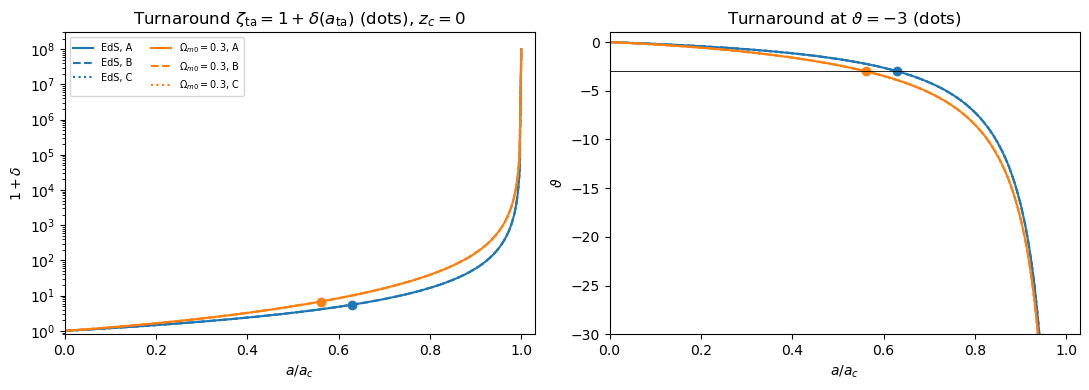

In [9]:
z_c = 0.0
N_c = -np.log(1 + z_c)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for Om0, color in [(1.0, 'tab:blue'), (0.3, 'tab:orange')]:
    for F, ls in zip((A, B, C), ['-', '--', ':']):
        model = F(Om0)
        r = model.turnaround_virial(z_c)
        sol = model.integrate(r['delta_i'], N_end=N_c + 0.5)          # tuned run
        N = np.linspace(np.log(model.a_i), sol.t_events[0][0], 3000)  # up to the collapse event
        y = sol.sol(N)
        d = np.array([model.delta(col) for col in y.T])               # delta (1/g in C)
        th = np.array([model.theta(col) for col in y.T])              # theta (reconstructed in A)
        lab = ('EdS' if Om0 == 1 else r'$\Omega_{m0}=0.3$') + f', {F.__name__}'
        ax[0].semilogy(np.exp(N - N_c), 1 + d, ls, color=color, label=lab)
        ax[1].plot(np.exp(N - N_c), th, ls, color=color, label=lab)
    ax[0].plot(r['a_ta_over_a_c'], r['zeta_ta'], 'o', color=color)    # turnaround (a_ta, zeta_ta)
    ax[1].plot(r['a_ta_over_a_c'], -3, 'o', color=color)
ax[1].axhline(-3, color='k', lw=0.6)
ax[0].set(xlim=(0, 1.03), ylim=(0.8, 3e8), xlabel=r'$a/a_c$', ylabel=r'$1+\delta$',
          title=r'Turnaround $\zeta_{\rm ta}=1+\delta(a_{\rm ta})$ (dots), $z_c=0$')
ax[1].set(xlim=(0, 1.03), ylim=(-30, 1), xlabel=r'$a/a_c$', ylabel=r'$\vartheta$',
          title=r'Turnaround at $\vartheta=-3$ (dots)')
ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()


A, B, C return same turnaround and virial values. 

For EdS: $a_{\rm ta}/a_c=0.6300$, $\zeta_{\rm ta}=5.5517$, $y=1/2$, $\Delta_{{\rm vir},m}=\Delta_{{\rm vir},c}=177.62$

For $\Omega_{m0}=0.3$: $a_{\rm ta}/a_c=0.5615$, $\zeta_{\rm ta}=6.837$, $y=0.4845<1/2$, $\Delta_{{\rm vir},m}=339.7$, $\Delta_{{\rm vir},c}=101.9$


#### Independent EdS benchmarks 
For $\delta_c=\frac{3}{20}(12\pi)^{2/3}=1.68647$, $a_{\rm ta}/a_c=2^{-2/3}$, $\zeta_{\rm ta}=(3\pi/4)^2$, $\Delta_{{\rm vir},m}=18\pi^2$ at $z_c=0,1,2$

In [10]:
# relative error of each formulation with respect to the exact values for different z_c
EDS_EXACT = {'delta_c': DELTA_C_EDS, 'a_ta_over_a_c': 2**(-2/3), 'zeta_ta': (3*np.pi/4)**2, 'Delta_vir_m': 18*np.pi**2}

eds = pd.DataFrame([F(1.0).turnaround_virial(z_c) for z_c in [0.0, 1.0, 2.0] for F in (A, B, C)])
eds.to_csv(DATA + 'eds_benchmarks.csv', index=False)

eds_err = eds[['formulation', 'z_c', 'delta_i']].copy()
for key, exact in EDS_EXACT.items():
    eds_err[key] = eds[key]/exact - 1                                # relative error
eds_err.style.format('{:.2e}', subset=list(EDS_EXACT) + ['delta_i'])


,formulation,z_c,delta_i,delta_c,a_ta_over_a_c,zeta_ta,Delta_vir_m
0,A,0.000000,1.69e-05,-4.77e-05,6.68e-05,3.16e-11,-2.00e-04
1,B,0.000000,1.69e-05,-4.77e-05,6.68e-05,5.62e-12,-2.00e-04
2,C,0.000000,1.69e-05,-4.77e-05,6.68e-05,-7.92e-11,-2.00e-04
3,A,1.000000,3.37e-05,-2.86e-05,6.68e-05,5.14e-11,-2.00e-04
4,B,1.000000,3.37e-05,-2.86e-05,6.68e-05,8.09e-12,-2.00e-04
5,C,1.000000,3.37e-05,-2.86e-05,6.68e-05,-1.40e-10,-2.00e-04
6,A,2.000000,5.06e-05,-9.45e-06,6.68e-05,-2.27e-12,-2.00e-04
7,B,2.000000,5.06e-05,-9.45e-06,6.68e-05,3.84e-12,-2.00e-04
8,C,2.000000,5.06e-05,-9.45e-06,6.68e-05,1.12e-10,-2.00e-04


Convergence with the collapse threshold (B, $z_c=0$)

In [11]:
rows = []
for d_inf in [1e5, 1e6, 1e7, 1e8]:
    r = B(1.0, threshold=d_inf).turnaround_virial(0.0)
    rows.append({'delta_inf': d_inf, **{key: r[key]/exact - 1 for key, exact in EDS_EXACT.items()}})
pd.DataFrame(rows).style.format('{:.2e}')


,delta_inf,delta_c,a_ta_over_a_c,zeta_ta,Delta_vir_m
0,1.00e+05,-2.12e-03,2.15e-03,5.04e-12,-6.41e-03
1,1.00e+06,-6.53e-04,6.72e-04,5.46e-12,-2.01e-03
2,1.00e+07,-1.92e-04,2.12e-04,5.58e-12,-6.35e-04
3,1.00e+08,-4.77e-05,6.68e-05,5.62e-12,-2.00e-04


#### Cosmology grid
$\Omega_{m0}\in\{0.2,0.3,0.4\}$, $\Omega_{\Lambda0}=1-\Omega_{m0}$, $z_c\in\{0,1,2\}$

In [12]:
grid = pd.DataFrame([F(Om0).turnaround_virial(z_c) for Om0 in [0.2, 0.3, 0.4]
                     for z_c in [0.0, 1.0, 2.0] for F in (A, B, C)])
grid.to_csv(DATA + 'lcdm_grid.csv', index=False)
grid[grid.formulation == 'C'].pivot_table(index='Omega_m0', columns='z_c',
                                          values=['delta_c', 'Delta_vir_m', 'Delta_vir_c'])

Delta_vir_c                     Delta_vir_m                       delta_c                    
z_c                0         1         2           0         1         2         0         1         2
Omega_m0                                                                                              
0.2         87.99949 144.33949 165.11044   439.99745 216.50924 189.57124 1.6716079 1.6828864 1.6852718
0.3        101.91427 155.44036 169.95514   339.71423 200.77713 184.64262 1.6754604  1.684212 1.6857477
0.4        114.47418 162.25477 172.56418   286.18545 192.67754 182.15108  1.678169 1.6849467 1.6859943

In [13]:
# max - min over A, B, C at each grid point
q = ['delta_c', 'a_ta_over_a_c', 'zeta_ta', 'Delta_vir_m', 'Delta_vir_c']
spread = grid.groupby(['Omega_m0', 'z_c'])[q]
(spread.max() - spread.min()).style.format('{:.1e}')

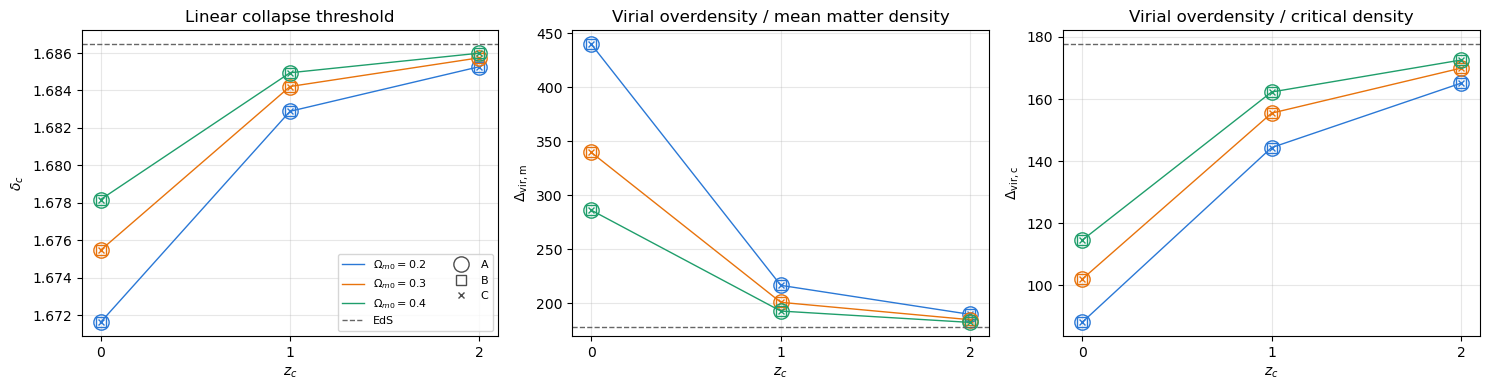

In [14]:
colors = {0.2: '#2a78d6', 0.3: '#e8730c', 0.4: '#1f9e6b'}          # one colour per Omega_m0
markers, sizes = {'A': 'o', 'B': 's', 'C': 'x'}, {'A': 11, 'B': 7, 'C': 5}   # one marker per formulation
panels = [('delta_c', r'$\delta_c$', DELTA_C_EDS, 'Linear collapse threshold'),
          ('Delta_vir_m', r'$\Delta_{\rm vir,m}$', 18*np.pi**2, 'Virial overdensity / mean matter density'),
          ('Delta_vir_c', r'$\Delta_{\rm vir,c}$', 18*np.pi**2, 'Virial overdensity / critical density')]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for axis, (key, label, eds_value, title) in zip(ax, panels):
    for Om0, color in colors.items():
        for F in 'ABC':
            sel = grid[(grid.Omega_m0 == Om0) & (grid.formulation == F)]
            axis.plot(sel.z_c, sel[key], markers[F], ms=sizes[F], mfc='none', color=color)
        sel = grid[(grid.Omega_m0 == Om0) & (grid.formulation == 'C')]
        axis.plot(sel.z_c, sel[key], '-', lw=1, color=color, label=fr'$\Omega_{{m0}}={Om0}$')
    axis.axhline(eds_value, color='0.4', ls='--', lw=1, label='EdS')     # 1.68647 and 18 pi^2
    axis.set(xlabel=r'$z_c$', ylabel=label, xticks=[0, 1, 2], title=title)
    axis.grid(alpha=0.3)
for F in 'ABC':       # legend entries for markers
    ax[0].plot([], [], markers[F], ms=sizes[F], mfc='none', color='0.3', label=F)
ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG + 'lcdm_grid.pdf'); plt.show()


In [15]:
# delta_c = delta_i linear growth D(a_c)/D(a_i) in LCDM / in EdS 
g = grid[grid.formulation == 'C'].copy()
eds_C = eds[eds.formulation == 'C'].set_index('z_c')          
growth = []
for Om0, z_c in zip(g.Omega_m0, g.z_c):
    model, a_c = C(Om0), 1/(1 + z_c)
    D = model.cosmo.growing_mode(np.array([model.a_i, a_c]), a_i=model.a_i*1e-3)[0]   # growth factor
    growth.append((D[1]/D[0]) / (a_c/model.a_i))    # LCDM growth / EdS growth (D = a)
g['growth LCDM / growth EdS'] = growth
g['delta_i LCDM / EdS'] = g.delta_i / g.z_c.map(eds_C.delta_i)
g['delta_c LCDM / EdS'] = g.delta_c / g.z_c.map(eds_C.delta_c)
g[['Omega_m0', 'z_c', 'growth LCDM / growth EdS', 'delta_i LCDM / EdS', 'delta_c LCDM / EdS']]


,Omega_m0,z_c,growth LCDM / growth EdS,delta_i LCDM / EdS,delta_c LCDM / EdS
2,0.2,0,0.70686944,1.4022881,0.99123457
5,0.2,1,0.92561449,1.0780984,0.9979035
8,0.2,2,0.97478812,1.0251447,0.99929887
11,0.3,0,0.77898102,1.2754086,0.99351905
14,0.3,1,0.95317013,1.0477558,0.99868952
17,0.3,2,0.98489459,1.0149117,0.99958101
20,0.4,0,0.83140178,1.1969245,0.9951252
23,0.4,1,0.9686128,1.0315011,0.99912516
26,0.4,2,0.99015446,1.009668,0.99972728


**Growth**: $\delta_c$ is the initial amplitude needed for collapse at $a_c$, evolved in linear theory from $a_i$ to $a_c$. In $\Lambda$ CDM, cosmologies with higher values of $\Lambda$ have slower growth of linear perturbations at late times, so for an overdensity to collapse at $a_c$, it needs larger initial amplitudes than in EdS.

In [16]:
# Delta_vir,m / 18pi^2 = [zeta_ta/(3pi/4)^2] x [(a_c/a_ta)^3/4] x [(1/2)/y]^3 ;  Delta_vir,c = Omega_m(a_c) Delta_vir,m
f = grid[grid.formulation == 'C'].copy()
f['Omega_m(a_c)'] = f.Delta_vir_c / f.Delta_vir_m
f['zeta_ta / zeta_ta(EdS)'] = f.zeta_ta / (3*np.pi/4)**2                       # turnaround density
f['(a_c/a_ta)^3 / (a_c/a_ta)^3(EdS)'] = (1/f.a_ta_over_a_c)**3 / 4            # background dilution, turnaround -> collapse
f['y^-3 / y^-3(EdS)'] = (0.5/f.y)**3                                          # virial compaction
f['Delta_vir_m / Delta_vir_m(EdS)'] = f.Delta_vir_m / (18*np.pi**2)
f['Delta_vir_c / Delta_vir_c(EdS)'] = f.Delta_vir_c / (18*np.pi**2)
f[['Omega_m0', 'z_c', 'Omega_m(a_c)', 'zeta_ta / zeta_ta(EdS)', '(a_c/a_ta)^3 / (a_c/a_ta)^3(EdS)',
   'y^-3 / y^-3(EdS)', 'Delta_vir_m / Delta_vir_m(EdS)', 'Delta_vir_c / Delta_vir_c(EdS)']]


,Omega_m0,z_c,Omega_m(a_c),zeta_ta / zeta_ta(EdS),(a_c/a_ta)^3 / (a_c/a_ta)^3(EdS),y^-3 / y^-3(EdS),Delta_vir_m / Delta_vir_m(EdS),Delta_vir_c / Delta_vir_c(EdS)
2,0.2,0,0.2,1.3418112,1.6175092,1.1411422,2.4767257,0.49534514
5,0.2,1,0.66666667,1.0645995,1.1121245,1.0293534,1.2187207,0.81248046
8,0.2,2,0.87096774,1.0207062,1.0355434,1.0095577,1.0670879,0.92939917
11,0.3,0,0.3,1.2315806,1.4124708,1.0992568,1.912236,0.5736708
14,0.3,1,0.77419355,1.0394013,1.0680289,1.0180655,1.1301653,0.87496672
17,0.3,2,0.92045455,1.012269,1.0209484,1.0056804,1.0393449,0.95666975
20,0.4,0,0.4,1.164513,1.2902356,1.0721658,1.6109249,0.64436996
23,0.4,1,0.84210526,1.0259549,1.0446436,1.0119578,1.0845731,0.91332474
26,0.4,2,0.94736842,1.0079511,1.0134953,1.003687,1.0253202,0.97135595


**Turnaround**: the spheres of overdensities reach turnaround when they stop expanding due to their self-gravity. In $\Lambda$ CDM, higher values of $\Lambda$ make the background expantion accelerate, which mean that overdensities need to reach higher values for turnaround. Indeed, $\zeta_{\rm ta}$ is larger for smaller values of $\Omega_m$. For higher values of $\Lambda$, it also happens earlier in relation to the collapse which makes $\Delta_{{\rm vir},m}$ increase.


**Virial prescription**: For a uniform sphere of mass $M$ and radius $R$ in flat background with matter and a cosmological constant $\Lambda$, the virial prescription is defined based in the assumptions:

- For the gravitational potential energy of the sphere $\quad U_G = -\dfrac{3GM^2}{5R}$ and the potential energy of the sphere in the $\Lambda$ field $\qquad U_\Lambda = -\dfrac{\Lambda M R^2}{10}$, turnaround happens when the sphere is at rest ($K=0$) and $\quad E_{\rm ta} = U_{G,\rm ta} + U_{\Lambda,\rm ta}$

- It virializes when $\quad 2K + U_G - 2U_\Lambda = 0 \;\Rightarrow\; E_{\rm vir} = \tfrac12 U_{G,\rm vir} + 2U_{\Lambda,\rm vir}$

- Imposing energy conservation $E_{\rm ta}=E_{\rm vir}$, with $y = R_{\rm vir}/R_{\rm ta}$ and $\lambda_{\rm ta} = \dfrac{\rho_\Lambda}{\rho_{\rm sph,ta}} = \dfrac{\Omega_\Lambda(a_{\rm ta})}{\Omega_m(a_{\rm ta})\,\zeta_{\rm ta}}$:
$$4\lambda_{\rm ta}\,y^3 - 2(1+\lambda_{\rm ta})\,y + 1 = 0, \qquad y\in(0,1/2] \quad (y=1/2 \text{ in EdS})$$

- The density of the virialized halo follows from the density at turnaround as:
$$\rho_{\rm vir} = \rho_{\rm sph,ta}\left(\frac{R_{\rm ta}}{R_{\rm vir}}\right)^3 = \zeta_{\rm ta}\,\bar\rho_m(a_{\rm ta})\,y^{-3}$$

The virial overdensity is defined by comparing $\rho_{\rm vir}$ with the background at the $a_c$ when the ideal sphere would reach $R=0$. Relative to the mean matter density, which has diluted as $a^{-3}$ since turnaround, $\bar\rho_m(a_c) = \bar\rho_m(a_{\rm ta})\,(a_{\rm ta}/a_c)^3$, and relative to the critical density, $\rho_{\rm crit} = \bar\rho_m/\Omega_m$:
$$\Delta_{{\rm vir},m}(a_c) = \frac{\rho_{\rm vir}}{\bar\rho_m(a_c)} = \zeta_{\rm ta}\left(\frac{a_c}{a_{\rm ta}}\right)^3 y^{-3}, \qquad
\Delta_{{\rm vir},c}(a_c) = \frac{\rho_{\rm vir}}{\rho_{\rm crit}(a_c)} = \Omega_m(a_c)\,\Delta_{{\rm vir},m}(a_c)$$

For larger $\Lambda$, then, halos reach equilibrium at a smaller radii and thus higher densities, which increases both $\Delta_{\rm vir,m}$ and $\Delta_{\rm vir,c}$. The virial prescription affects $\Delta_{\rm vir,m}$, $\Delta_{\rm vir,c}$ and $y$, values defined to describe dynamics and an equilibrium condition after the turnaround that the equations for $\delta_c$ do not, since they describe an spherical collapse to a point.

**Reference density**: $\Delta_{\rm vir,m}$ and $\Delta_{\rm vir,c}$ describe the halo density $\rho_{\rm vir}$ compared with the mean matter density $\bar\rho_m$ and the critical density $\rho_{\rm crit}=\bar\rho_m+\rho_\Lambda$. Beacuse $\bar\rho_m$ dilutes as $a^{-3}$, while $\rho_\Lambda$ stays constant, at late times $\rho_{\rm crit}$ is much larger than $\bar\rho_m$ ($\Omega_m(a_c)=\bar\rho_m/\rho_{\rm crit}<1$). For a same halo, then, towards low $z_c$, $\Delta_{\rm vir,m}$ grows while $\Delta_{\rm vir,c}$ decreases. In EdS, where $\Lambda=0$, the two reference densities are equal, as for at high $z_c$, when $\Lambda$ is still negligible.


#### Convergence
Each setting is changed one at a time from the defaults ($a_i=10^{-5}$, `rtol=1e-10`, `atol=1e-13`, $\delta_\infty=10^8$, $\epsilon=10^{-8}$), and $\delta_i$ is retuned for every run. Cases: EdS and flat ΛCDM $\Omega_{m0}=0.3$, both at $z_c=0$. "spread" = max − min over A, B, C; `nfev` = right-hand-side evaluations of the tuned run.


In [17]:
def compare_formulations(Om0, z_c=0.0, **settings):
    """Runs A, B, C with same settings and returns one table row:
    delta_c of each formulation, cross-formulation spreads, largest event residual and cost"""
    r = {F.__name__: F(Om0, **settings).turnaround_virial(z_c) for F in (A, B, C)}
    dc = np.array([r[F]['delta_c'] for F in 'ABC'])
    dv = np.array([r[F]['Delta_vir_m'] for F in 'ABC'])
    return dict(Omega_m0=Om0, **settings,
                delta_c_A=dc[0], delta_c_B=dc[1], delta_c_C=dc[2], spread_delta_c=np.ptp(dc),
                Delta_vir_m_B=r['B']['Delta_vir_m'], spread_Delta_vir_m=np.ptp(dv),
                max_event_residual=max(abs(r[F]['event_residual']) for F in 'ABC'),
                **{f'nfev_{F}': r[F]['nfev'] for F in 'ABC'})

##### Initial epoch $a_i$

In [18]:
conv_ai = pd.DataFrame([compare_formulations(Om0, a_i=ai) for Om0 in [1.0, 0.3] for ai in [1e-3, 1e-4, 1e-5]])
conv_ai.to_csv(DATA + 'convergence_ai.csv', index=False)
conv_ai

,Omega_m0,a_i,delta_c_A,delta_c_B,delta_c_C,spread_delta_c,Delta_vir_m_B,spread_Delta_vir_m,max_event_residual,nfev_A,nfev_B,nfev_C
0,1,0.001,1.6895862,1.6895862,1.6895862,1.0486567e-10,177.61729,3.0884792e-08,2.9616159e-15,2207,2333,2636
1,1,0.0001,1.6866799,1.6866799,1.6866799,9.6994635e-11,177.61729,2.4025155e-08,3.3048729e-15,2297,2423,2876
2,1,1e-05,1.6863898,1.6863898,1.6863898,9.7508446e-11,177.61729,7.3152364e-09,4.5310037e-15,2357,2483,3101
3,0.3,0.001,1.6795126,1.6795126,1.6795126,1.0167467e-10,339.71423,8.0796838e-08,1.2006193e-14,2132,2189,2465
4,0.3,0.0001,1.675828,1.675828,1.675828,1.0078494e-10,339.71423,1.3942838e-08,4.3618032e-15,2222,2279,2690
5,0.3,1e-05,1.6754604,1.6754604,1.6754604,1.0005063e-10,339.71423,6.6380551e-08,8.3296438e-15,2297,2339,2942


##### Tolerances

In [19]:
tols = [(1e-6, 1e-9), (1e-8, 1e-11), (1e-10, 1e-13), (1e-12, 1e-15), (1e-10, 1e-9), (1e-10, 1e-6)]
conv_tol = pd.DataFrame([compare_formulations(Om0, rtol=rt, atol=at) for Om0 in [1.0, 0.3] for rt, at in tols])
conv_tol.to_csv(DATA + 'convergence_tol.csv', index=False)
conv_tol

,Omega_m0,rtol,atol,delta_c_A,delta_c_B,delta_c_C,spread_delta_c,Delta_vir_m_B,spread_Delta_vir_m,max_event_residual,nfev_A,nfev_B,nfev_C
0,1,1e-06,1e-09,1.6863928,1.6863923,1.6863904,2.3086659e-06,177.61736,0.00028332767,3.2540323e-15,1184,1022,1019
1,1,1e-08,1e-11,1.6863898,1.6863898,1.6863898,1.2000638e-08,177.61729,1.6855761e-06,1.2134562e-14,2273,1802,1760
2,1,1e-10,1e-13,1.6863898,1.6863898,1.6863898,9.7508446e-11,177.61729,7.3152364e-09,4.5310037e-15,2357,2483,3101
3,1,1e-12,1e-15,1.6863898,1.6863898,1.6863898,3.4661163e-13,177.61729,2.1401547e-10,3.3320546e-15,4472,3467,3722
4,1,1e-10,1e-09,1.6863899,1.6863899,1.6863898,9.9732514e-08,177.61729,7.3633714e-08,6.9182872e-15,2387,2489,3008
5,1,1e-10,1e-06,1.6864426,1.6864324,1.6863899,5.2642122e-05,177.61729,2.9198296e-05,9.8729177e-14,2090,1979,2060
6,0.3,1e-06,1e-09,1.675463,1.6754629,1.6754613,1.6329293e-06,339.71433,0.00094202154,2.410133e-14,1142,968,953
7,0.3,1e-08,1e-11,1.6754604,1.6754604,1.6754604,1.0099421e-08,339.71423,3.947799e-06,1.299165e-14,2207,1748,1667
8,0.3,1e-10,1e-13,1.6754604,1.6754604,1.6754604,1.0005063e-10,339.71423,6.6380551e-08,8.3296438e-15,2297,2339,2942
9,0.3,1e-12,1e-15,1.6754604,1.6754604,1.6754604,3.7858605e-13,339.71423,2.4357405e-10,4.3709713e-15,4352,3377,3602


##### Collapse threshold ($\epsilon = 1/\delta_\infty$ for C)

In [20]:
rows = []
for Om0 in [1.0, 0.3]:
    for d_inf in [1e5, 1e6, 1e7, 1e8]:
        r = {F.__name__: F(Om0, threshold=(1/d_inf if F is C else d_inf)).turnaround_virial(0.0) for F in (A, B, C)}
        dc = np.array([r[F]['delta_c'] for F in 'ABC'])
        rows.append(dict(Omega_m0=Om0, delta_inf=d_inf, eps=1/d_inf, delta_c_B=r['B']['delta_c'],
                         spread_delta_c=np.ptp(dc), a_ta_over_a_c_B=r['B']['a_ta_over_a_c'],
                         Delta_vir_m_B=r['B']['Delta_vir_m'],
                         max_event_residual=max(abs(r[F]['event_residual']) for F in 'ABC'),
                         **{f'nfev_{F}': r[F]['nfev'] for F in 'ABC'}))
conv_th = pd.DataFrame(rows)
conv_th.to_csv(DATA + 'convergence_threshold.csv', index=False)
conv_th


,Omega_m0,delta_inf,eps,delta_c_B,spread_delta_c,a_ta_over_a_c_B,Delta_vir_m_B,max_event_residual,nfev_A,nfev_B,nfev_C
0,1,100000,1e-05,1.68289,9.7031716e-11,0.63131275,176.51376,5.6743923e-15,1697,1769,2399
1,1,1000000,1e-06,1.6853694,9.7505559e-11,0.63038402,177.29508,5.504692e-15,1907,2006,2642
2,1,10000000,1e-07,1.6861456,9.749157e-11,0.63009385,177.54013,1.7974069e-15,2132,2258,2858
3,1,1e+08,1e-08,1.6863898,9.7508446e-11,0.6300026,177.61729,4.5310037e-15,2357,2483,3101
4,0.3,100000,1e-05,1.6721165,1.0025802e-10,0.56312113,337.50725,5.8822241e-15,1622,1613,2213
5,0.3,1000000,1e-06,1.6744872,1.0003176e-10,0.56194332,339.07104,5.3100212e-15,1847,1877,2456
6,0.3,10000000,1e-07,1.6752277,9.9997344e-11,0.56157681,339.56036,4.7872338e-15,2072,2102,2699
7,0.3,1e+08,1e-08,1.6754604,1.0005063e-10,0.56146175,339.71423,8.3296438e-15,2297,2339,2942


##### Failure modes

In [21]:
# loose tolerances: relative shift of delta_c with respect to the default run of each formulation
default = {F.__name__: F(1.0).turnaround_virial(0.0)['delta_c'] for F in (A, B, C)}
rows = []
for rt, at in [(1e-4, 1e-13), (1e-10, 1e-5), (1e-10, 1e-4)]:
    for F in (A, B, C):
        r = F(1.0, rtol=rt, atol=at).turnaround_virial(0.0)
        rows.append(dict(rtol=rt, atol=at, formulation=F.__name__,
                         delta_c_shift=r['delta_c']/default[F.__name__] - 1, nfev=r['nfev']))
pd.DataFrame(rows).pivot_table(index=['rtol', 'atol'], columns='formulation', values=['delta_c_shift', 'nfev'])

delta_c_shift                             nfev          
formulation               A             B             C    A    B    C
rtol   atol                                                           
1e-10  1e-05  0.00032062008 0.00021178991 6.8242165e-07 1955 1760 1601
       0.0001 0.00036692771 0.00027213845 2.6705839e-06 1835 1589 1226
0.0001 1e-13  0.00010297078 7.2601363e-05 0.00011183601  737  656  650

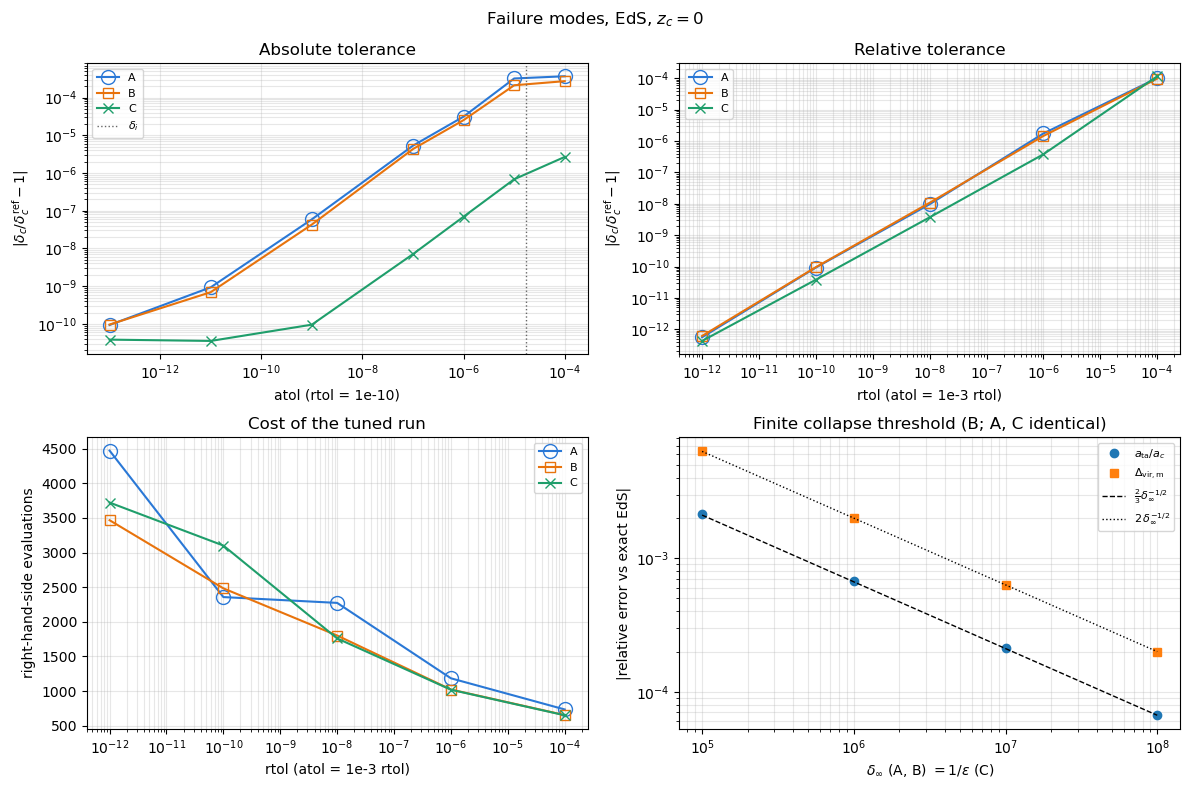

In [22]:
# failure modes, EdS z_c = 0: error of delta_c against the tightest run (rtol = 1e-13, atol = 1e-16) of each formulation
atols = [1e-13, 1e-11, 1e-9, 1e-7, 1e-6, 1e-5, 1e-4]                 # with rtol = 1e-10
rtols = [1e-4, 1e-6, 1e-8, 1e-10, 1e-12]                              # with atol = 1e-3 rtol
styles = {'A': ('o', 10, '#2a78d6'), 'B': ('s', 7, '#e8730c'), 'C': ('x', 7, '#1f9e6b')}

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for F in (A, B, C):
    m, s, col = styles[F.__name__]
    ref = F(1.0, rtol=1e-13, atol=1e-16).turnaround_virial(0.0)['delta_c']
    err_atol = [abs(F(1.0, atol=at).turnaround_virial(0.0)['delta_c']/ref - 1) for at in atols]
    runs_rtol = [F(1.0, rtol=rt, atol=rt*1e-3).turnaround_virial(0.0) for rt in rtols]
    err_rtol = [abs(r['delta_c']/ref - 1) for r in runs_rtol]
    ax[0, 0].loglog(atols, err_atol, m + '-', ms=s, mfc='none', color=col, label=F.__name__)
    ax[0, 1].loglog(rtols, err_rtol, m + '-', ms=s, mfc='none', color=col, label=F.__name__)
    ax[1, 0].semilogx(rtols, [r['nfev'] for r in runs_rtol], m + '-', ms=s, mfc='none', color=col, label=F.__name__)
ax[0, 0].axvline(1.686e-5, color='0.4', ls=':', lw=1, label=r'$\delta_i$')   # initial amplitude
ax[0, 0].set(xlabel='atol (rtol = 1e-10)', ylabel=r'$|\delta_c/\delta_c^{\rm ref}-1|$', title='Absolute tolerance')
ax[0, 1].set(xlabel='rtol (atol = 1e-3 rtol)', ylabel=r'$|\delta_c/\delta_c^{\rm ref}-1|$', title='Relative tolerance')
ax[1, 0].set(xlabel='rtol (atol = 1e-3 rtol)', ylabel='right-hand-side evaluations', title='Cost of the tuned run')

# finite threshold (common to A, B, C): errors of turnaround and virial values against the exact EdS ones
th = conv_th[conv_th.Omega_m0 == 1.0]
ax[1, 1].loglog(th.delta_inf, np.abs(th.a_ta_over_a_c_B/2**(-2/3) - 1), 'o', label=r'$a_{\rm ta}/a_c$')
ax[1, 1].loglog(th.delta_inf, np.abs(th.Delta_vir_m_B/(18*np.pi**2) - 1), 's', label=r'$\Delta_{\rm vir,m}$')
ax[1, 1].loglog(th.delta_inf, 2/3*th.delta_inf**-0.5, 'k--', lw=1, label=r'$\frac{2}{3}\delta_\infty^{-1/2}$')
ax[1, 1].loglog(th.delta_inf, 2*th.delta_inf**-0.5, 'k:', lw=1, label=r'$2\,\delta_\infty^{-1/2}$')
ax[1, 1].set(xlabel=r'$\delta_\infty$ (A, B) $=1/\epsilon$ (C)', ylabel='|relative error vs exact EdS|',
             title='Finite collapse threshold (B; A, C identical)')
for axis in ax.flat:
    axis.grid(alpha=0.3, which='both'); axis.legend(fontsize=8)
fig.suptitle(r'Failure modes, EdS, $z_c=0$')
plt.tight_layout(); plt.savefig(FIG + 'failure_modes.pdf'); plt.show()


The figure separates the failure modes: A and B lose accuracy when `atol` approaches the initial amplitude $\delta_i$, while C does not ($g=1/\delta_i$ is large). `rtol` limits all three equally (error $\approx$ `rtol`), and A is the most expensive at the tightest tolerance. The threshold produces the same error in all formulations, $\propto\delta_\infty^{-1/2}$ and is the dominant error.
